# Практична робота №10
## Розпізнавання за клавіатурним почерком

Програма вимірює час між натисканнями клавіш, зберігає навчальні зразки й порівнює з ними нові спроби. Для перевірки використовую критерії Фішера та Стьюдента.


In [1]:
%pip install scipy matplotlib



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Як працює перевірка

У фразі «Ходи куди хочеш» 15 символів із пробілами. Між ними отримую 14 інтервалів. Час натискання Enter і Shift до вибірки не входить.

Спочатку програма перевіряє інтервали за алгоритмом методички. Кожен інтервал порівнюється з рештою: обчислюються середнє, дисперсія та значення |yᵢ−Mᵢ|/Sᵢ. Для пошуку грубих помилок використовую α = 0,05 і критичне значення t(0,975; m−2). Після видалення інтервалу перевірка повторюється.

Якщо залишилося менше 14 інтервалів, спроба відхиляється. У навчанні вона не стає зразком, а під час перевірки зараховується як відмова користувачу.

Придатну спробу порівнюю з кожним зразком однакової довжини:

- критерій Фішера порівнює дисперсії: F = max(s₁², s₂²)/min(s₁², s₂²), критичне значення F(1−α; n−1, n−1);
- критерій Стьюдента порівнює середні: sₚ² = (s₁²+s₂²)/2, t = |M₁−M₂|/sqrt(sₚ²·2/n), критичне значення t(1−α/2; 2n−2).

Збіг зараховується, якщо пройдено обидва критерії. Далі P = кількість збігів / кількість зразків. Для допуску P має бути не меншим за обраний поріг 0,9 або 0,95. Значення P показує частку збігів, а не точність програми.

Окремо показую, як навчальні зразки збігаються між собою при α = 0,05. Цей результат не змінює набір зразків. Під час перевірки зразки не доповнюються.


In [2]:
import json
import math
import time
import uuid
from pathlib import Path
import tkinter as tk
from tkinter import ttk, messagebox
from scipy.stats import t, f
import matplotlib.pyplot as plt
folder = Path("prac10")
folder.mkdir(exist_ok=True)
version = 3


In [3]:
def get_stats(values):
    if len(values) < 2:
        raise ValueError("Замало інтервалів для розрахунку дисперсії.")
    mean = sum(values) / len(values)
    var = sum((x - mean) ** 2 for x in values) / (len(values) - 1)
    return mean, var

def clean(values):
    values, removed = list(values), []
    while len(values) >= 3:
        limit = float(t.ppf(0.975, len(values) - 2))
        for i, value in enumerate(values):
            mean, var = get_stats(values[:i] + values[i + 1:])
            diff = abs(value - mean)
            score = diff / math.sqrt(var) if var > 0 else (math.inf if diff else 0.0)
            if score > limit:
                removed.append(values.pop(i))
                break
        else:
            break
    return values, removed

def make_sample(raw, phrase, typed):
    raw = list(raw)
    n = len(phrase) - 1
    reason = ""
    if typed != phrase:
        reason = "Фраза не збігається зі зразком."
    elif len(raw) != n or any(not math.isfinite(v) or v <= 0 for v in raw):
        reason = "Не вдалося правильно записати інтервали."
    values, removed = clean(raw) if not reason else ([], [])
    if not reason and len(values) != n:
        reason = f"Після очищення залишилося {len(values)} інтервалів із {n}. Спробу відхилено."
    mean, var = get_stats(values) if len(values) >= 2 else (None, None)
    return {"raw": raw, "values": values, "removed": removed,
            "mean": mean, "var": var, "valid": not reason, "reason": reason}

def compare(x, y, alpha):
    if len(x) != len(y) or len(x) < 3:
        raise ValueError("Для порівняння потрібно щонайменше 3 інтервали й однакова їх кількість в обох спробах.")
    if not 0 < alpha < 1:
        raise ValueError("Рівень значущості має бути між 0 та 1.")
    if any(not math.isfinite(v) or v <= 0 for v in list(x) + list(y)):
        raise ValueError("Значення інтервалів мають бути більші за нуль, без пропусків та нескінченності.")
    n = len(x)
    mx, vx = get_stats(x)
    my, vy = get_stats(y)
    large, small = max(vx, vy), min(vx, vy)
    fp = large / small if small > 0 else (math.inf if large else 1.0)
    ft = float(f.ppf(1 - alpha, n - 1, n - 1))
    pooled = (vx + vy) / 2
    se = math.sqrt(pooled * 2 / n)
    tp = abs(mx - my) / se if se > 0 else (math.inf if mx != my else 0.0)
    tt = float(t.ppf(1 - alpha / 2, 2 * n - 2))
    return fp, ft, tp, tt, bool(fp <= ft and tp <= tt)

def check(profile, sample, alpha, threshold):
    if threshold not in (0.9, 0.95):
        raise ValueError("Оберіть поріг 0,9 або 0,95.")
    refs = profile["samples"]
    n = len(profile["phrase"]) - 1
    if not refs:
        raise ValueError("Немає збережених зразків. Спочатку проведіть навчання.")
    if any(not s["valid"] or len(s["values"]) != n for s in refs):
        raise ValueError("У зразках різна кількість інтервалів. Потрібне нове навчання.")
    if not sample["valid"] or len(sample["values"]) != n:
        return [], None, False
    rows = [compare(s["values"], sample["values"], alpha) for s in refs]
    probability = sum(row[4] for row in rows) / len(rows)
    return rows, probability, probability >= threshold

def error_rates(records):
    own = [r for r in records if r["person"] == "Власник"]
    other = [r for r in records if r["person"] == "Інша людина"]
    return len(own), sum(not r["accepted"] for r in own), len(other), sum(r["accepted"] for r in other)

def consistency(samples, alpha=0.05):
    if len(samples) < 2:
        return []
    return [sum(compare(s["values"], other["values"], alpha)[4]
                for j, other in enumerate(samples) if i != j) / (len(samples) - 1)
            for i, s in enumerate(samples)]

def save_data(path, data):
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)


### Робота з програмою

Спочатку обираю навчання та кількість спроб. Після кожної фрази натискаю Enter. У лічильнику враховуються всі надіслані спроби, тому при виборі 10 робота закінчиться після десятого введення.

У файл записуються всі навчальні спроби. Для порівняння використовуються лише прийняті зразки. Нове завершене навчання замінює попередній профіль. Якщо жодного зразка немає, перейти до перевірки не вийде.

Для перевірки власника залишаю позначку «Перевіряється власник», для іншої людини знімаю її. Позначка впливає лише на підрахунок помилок. Власник та інша людина проходять окремі серії з тими самими зразками й налаштуваннями.

Backspace, Delete або Esc скидають поточну фразу. До натискання Enter вона не рахується як виконана спроба. При втраті фокусу поля незавершена фраза теж скидається.


In [4]:
class App:

    def __init__(self, root):
        self.root = root
        self.active = False
        self.profile = None
        self.records = []
        self.held = set()
        self.times, self.typed, self.last = [], "", None
        root.title("Клавіатурний почерк")
        root.geometry("980x820")
        frame = ttk.Frame(root, padding=12)
        frame.pack(fill="both", expand=True)
        self.mode = tk.StringVar(value="Навчання")
        self.count = tk.StringVar(value="10")
        self.alpha = tk.StringVar(value="0.05")
        self.threshold = tk.StringVar(value="0.9")
        self.owner = tk.BooleanVar(value=True)
        self.phrase = tk.StringVar(value="Ходи куди хочеш")
        self.controls = []
        fields = [("Режим", self.mode, ["Навчання", "Перевірка"]),
                  ("Кількість спроб", self.count, [3, 4, 5, 6, 7, 8, 9, 10, 20, 30]),
                  ("Рівень значущості α", self.alpha, [0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001]),
                  ("Поріг P для допуску", self.threshold, ["0.9", "0.95"])]
        for label, var, values in fields:
            row = ttk.Frame(frame)
            row.pack(fill="x", pady=3)
            ttk.Label(row, text=label, width=30).pack(side="left")
            box = ttk.Combobox(row, textvariable=var, values=values, state="readonly", width=24)
            box.pack(side="left")
            self.controls.append(box)
        self.owner_box = ttk.Checkbutton(frame, text="Перевіряється власник", variable=self.owner)
        self.owner_box.pack(anchor="w", pady=5)
        ttk.Label(frame, text="Фраза для введення:").pack(anchor="w")
        self.phrase_box = ttk.Entry(frame, textvariable=self.phrase)
        self.phrase_box.pack(fill="x")
        buttons = ttk.Frame(frame)
        buttons.pack(pady=6)
        self.button = ttk.Button(buttons, text="Почати", command=self.start)
        self.button.pack(side="left", padx=4)
        self.stop_button = ttk.Button(buttons, text="Зупинити", command=self.stop, state="disabled")
        self.stop_button.pack(side="left", padx=4)
        self.status = tk.StringVar(value="Оберіть режим і натисніть «Почати».")
        self.progress = tk.StringVar(value="")
        ttk.Label(frame, textvariable=self.status, wraplength=920).pack(anchor="w")
        ttk.Label(frame, textvariable=self.progress, wraplength=920).pack(anchor="w")
        ttk.Label(frame, text="Після фрази натисніть Enter. Щоб набрати заново — Backspace або Esc.").pack(anchor="w", pady=4)
        self.entry = ttk.Entry(frame, font=("Arial", 16), state="disabled")
        self.entry.pack(fill="x", pady=5)
        self.entry.bind("<KeyPress>", self.key_down)
        self.entry.bind("<KeyRelease>", lambda e: self.held.discard(e.keycode))
        self.entry.bind("<FocusOut>", lambda e: self.reset_input() if self.active else None)
        self.entry.bind("<<Paste>>", lambda e: "break")
        self.entry.bind("<Button-2>", lambda e: "break")
        log = ttk.Frame(frame)
        log.pack(fill="both", expand=True)
        self.output = tk.Text(log, height=22, wrap="word", state="disabled")
        scroll = ttk.Scrollbar(log, command=self.output.yview)
        self.output.configure(yscrollcommand=scroll.set)
        scroll.pack(side="right", fill="y")
        self.output.pack(side="left", fill="both", expand=True)

    def show(self, text):
        self.output.configure(state="normal")
        self.output.delete("1.0", "end")
        self.output.insert("end", text)
        self.output.configure(state="disabled")

    def reset_input(self):
        self.times, self.typed, self.last = [], "", None
        self.held.clear()
        self.entry.delete(0, "end")

    def lock(self, active):
        self.active = active
        for box in self.controls:
            box.configure(state="disabled" if active else "readonly")
        self.owner_box.configure(state="disabled" if active else "normal")
        self.phrase_box.configure(state="disabled" if active else "normal")
        self.button.configure(state="disabled" if active else "normal")
        self.stop_button.configure(state="normal" if active else "disabled")
        self.entry.configure(state="normal")
        self.reset_input()
        if not active:
            self.entry.configure(state="disabled")

    def start(self):
        if self.active:
            return
        try:
            self.total = int(self.count.get())
            self.a = float(self.alpha.get().replace(",", "."))
            self.cutoff = float(self.threshold.get().replace(",", "."))
            if self.total not in (3, 4, 5, 6, 7, 8, 9, 10, 20, 30):
                raise ValueError("Оберіть кількість спроб зі списку.")
            if not 0 < self.a < 1 or self.cutoff not in (0.9, 0.95):
                raise ValueError("Перевірте рівень значущості та поріг P.")
            self.person = "Власник" if self.owner.get() else "Інша людина"
            if self.mode.get() == "Перевірка":
                path = folder / "etalon.json"
                if not path.exists():
                    raise ValueError("Спочатку проведіть навчання.")
                profile = json.loads(path.read_text(encoding="utf-8"))
                if profile.get("version") != version:
                    raise ValueError("Цей файл зразків створено в іншій версії. Проведіть навчання заново.")
                if not profile["samples"]:
                    raise ValueError("У навчанні не залишилося придатних зразків. Повторіть його.")
                n = len(profile["phrase"]) - 1
                if n < 3 or any(not s["valid"] or len(s["values"]) != n or
                               any(not math.isfinite(v) or v <= 0 for v in s["values"])
                               for s in profile["samples"]):
                    raise ValueError("Не вдалося прочитати зразки: перевірте кількість та значення інтервалів.")
                self.profile = profile
                self.phrase.set(profile["phrase"])
                path = folder / "checks.json"
                history = json.loads(path.read_text(encoding="utf-8")) if path.exists() else []
                self.records = [r for r in history if r["profile_id"] == profile["id"]]
            elif len(self.phrase.get()) < 4:
                raise ValueError("Введіть фразу довжиною хоча б 4 символи.")
            self.samples, self.training, self.session = [], [], []
            self.done = self.rejected = 0
            self.series_id = uuid.uuid4().hex
            self.saved_training = False
            self.lock(True)
            n = len(self.phrase.get()) - 1
            self.show(f"Потрібно {n} інтервалів у кожній спробі.\n"
                      f"Заплановано {self.total} спроб. Відхилені теж враховуються.")
            self.progress.set(f"Виконано спроб: 0/{self.total}")
            self.status.set(f"Спроба 1/{self.total}. Фраза: {self.phrase.get()}")
            self.entry.focus_set()
        except (OSError, ValueError, KeyError, TypeError) as exc:
            messagebox.showerror("Початок роботи", str(exc), parent=self.root)

    def key_down(self, event):
        if not self.active:
            return "break"
        if event.keysym in ("Escape", "BackSpace", "Delete"):
            self.reset_input()
        elif event.keysym in ("Return", "KP_Enter"):
            if self.typed:
                self.finish_input()
        elif event.char and event.char.isprintable() and not event.state & 0xC:
            if event.keycode in self.held:
                return "break"
            self.held.add(event.keycode)
            now = time.perf_counter()
            if self.last is not None:
                self.times.append(now - self.last)
            self.last = now
            self.typed += event.char
            self.entry.insert("end", event.char)
        return "break"

    def stop(self):
        if not self.active:
            return
        self.lock(False)
        self.status.set("Навчання зупинено. Ці зразки не збережено."
                        if self.mode.get() == "Навчання" else
                        "Перевірку зупинено. Виконані спроби збережено.")

    def finish_input(self):
        try:
            sample = make_sample(self.times, self.phrase.get(), self.typed)
            n = len(self.phrase.get()) - 1
            text = f"Спроба {self.done + 1}/{self.total}\n"
            text += "Інтервали між клавішами, с: " + ", ".join(f"{v:.5f}" for v in sample["raw"]) + "\n"
            text += f"Залишилося інтервалів: {len(sample['values'])}/{n}; вилучено: {len(sample['removed'])}.\n"
            if sample["removed"]:
                text += "Вилучені інтервали, с: " + ", ".join(f"{v:.5f}" for v in sample["removed"]) + "\n"
            if sample["mean"] is not None:
                text += f"Середнє: {sample['mean']:.6f} с; дисперсія: {sample['var']:.8f} с².\n"
            if not sample["valid"]:
                text += "Причина відхилення: " + sample["reason"] + "\n"
            if self.mode.get() == "Навчання":
                sample["attempt"] = self.done + 1
                self.training.append(sample)
                if sample["valid"]:
                    self.samples.append(sample)
                else:
                    self.rejected += 1
                text += f"Прийнято зразків: {len(self.samples)}; відхилено спроб: {self.rejected}.\n"
                if self.done + 1 == self.total:
                    profile = {"version": version, "id": uuid.uuid4().hex, "phrase": self.phrase.get(),
                               "n": n, "samples": self.samples, "training": self.training,
                               "rejected_count": self.rejected}
                    save_data(folder / "etalon.json", profile)
                    self.saved_training = True
                    text += "Зразки збережено. Перевірки зі старими зразками до нового підсумку не входять.\n"
                    if self.samples:
                        k = len(self.samples)
                        text += f"Для порога {self.cutoff} потрібно {math.ceil(k * self.cutoff)} збігів із {k}.\n"
                        if k < 10:
                            text += "Зразків небагато. За потреби проведіть навчання з більшою кількістю спроб.\n"
                        scores = consistency(self.samples)
                        for ref, score in zip(self.samples, scores):
                            text += f"Навчальна спроба №{ref['attempt']}: збіги з іншими зразками {score:.3f}.\n"
                    else:
                        text += "Жодного зразка не прийнято. Для перевірки потрібно повторити навчання.\n"
            else:
                rows, probability, accepted = check(self.profile, sample, self.a, self.cutoff)
                for ref, row in zip(self.profile["samples"], rows):
                    fp, ft, tp, tt, match = row
                    text += (f"Зразок зі спроби №{ref['attempt']}: "
                             f"M={ref['mean']:.6f}, s²={ref['var']:.8f}; "
                             f"F={fp:.3f}/{ft:.3f}, t={tp:.3f}/{tt:.3f}; "
                             + ("збіг" if match else "немає збігу") + ".\n")
                record = {"profile_id": self.profile["id"], "series_id": self.series_id,
                          "attempt": self.done + 1, "person": self.person, "alpha": self.a,
                          "threshold": self.cutoff, "sample": sample, "p": probability, "accepted": accepted}
                save_data(folder / "checks.json", self.records + [record])
                self.records.append(record)
                self.session.append(record)
                self.rejected += not sample["valid"]
                if probability is not None:
                    text += f"P = {sum(row[4] for row in rows)}/{len(rows)} = {probability:.3f}.\n"
                else:
                    text += "P не розраховано: спробу відхилено ще до порівняння.\n"
                text += "Рішення: допущено.\n" if accepted else "Рішення: відмовлено.\n"
                n0, n1, m0, n2 = error_rates(self.session)
                if self.person == "Власник":
                    text += f"Помилка першого роду: {n1}/{n0} = {n1 / n0:.1%}.\n"
                else:
                    text += f"Помилка другого роду: {n2}/{m0} = {n2 / m0:.1%}.\n"
                correct = n0 - n1 + m0 - n2
                text += f"Правильних рішень: {correct}/{len(self.session)} = {correct / len(self.session):.1%}."
            self.done += 1
            self.show(text)
            self.progress.set(f"Виконано спроб: {self.done}/{self.total}; відхилено: {self.rejected}"
                              + (f"; зразків: {len(self.samples)}" if self.mode.get() == "Навчання" else ""))
            self.reset_input()
            if self.done == self.total:
                self.lock(False)
                if self.mode.get() == "Навчання":
                    self.status.set(f"Навчання закінчено: {self.done} спроб, {len(self.samples)} зразків. "
                                    + ("Тепер можна перевірити користувача." if self.samples else
                                       "Зразків немає. Повторіть навчання."))
                else:
                    self.status.set("Перевірку завершено. Результати збережено.")
            else:
                self.status.set(f"Наступна спроба: {self.done + 1}/{self.total}. Фраза: {self.phrase.get()}")
        except (OSError, ValueError, KeyError, TypeError) as exc:
            self.stop()
            messagebox.showerror("Помилка обробки", str(exc), parent=self.root)


In [5]:
root = tk.Tk()
app = App(root)
root.mainloop()


### Результати

Помилка першого роду — це відмови власнику, поділені на кількість його перевірок. Помилка другого роду — допуски іншої людини, поділені на кількість її перевірок.

Загальна точність — кількість правильних рішень, поділена на кількість усіх перевірок. Правильне рішення — допустити власника або відмовити іншій людині. Відхилені до порівняння спроби теж враховуються.

Якщо під час очищення видалено хоча б один інтервал, уся спроба відхиляється. Тому програма може відмовити навіть при правильно набраному тексті.

Метод порівнює середній час та дисперсію, але не враховує порядок інтервалів. Через це людей зі схожими параметрами друку він може не розрізнити.


Фраза: Ходи куди хочеш | потрібно інтервалів: 14
Навчальних спроб: 10
Збережених зразків: 4
Відхилених навчальних спроб: 6
Спроба | інтервалів | середнє, с | дисперсія, с² | прийнято
1 | 13/14 | 0.219082 | 0.00386313 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраковано.
2 | 13/14 | 0.199614 | 0.00522053 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраковано.
3 | 13/14 | 0.214402 | 0.00531190 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраковано.
4 | 14/14 | 0.200894 | 0.00371610 | Так
5 | 14/14 | 0.211045 | 0.00396135 | Так
6 | 14/14 | 0.210588 | 0.00229723 | Так
7 | 12/14 | 0.202831 | 0.00475473 | Ні
  Причина: Після очищення залишилося 12 інтервалів із 14. Спробу забраковано.
8 | 12/14 | 0.195383 | 0.00251999 | Ні
  Причина: Після очищення залишилося 12 інтервалів із 14. Спробу забраковано.
9 | 13/14 | 0.218770 | 0.00455759 | Ні
  Причина: Після очищення залишилося 13 інтервалів із 14. Спробу забраков

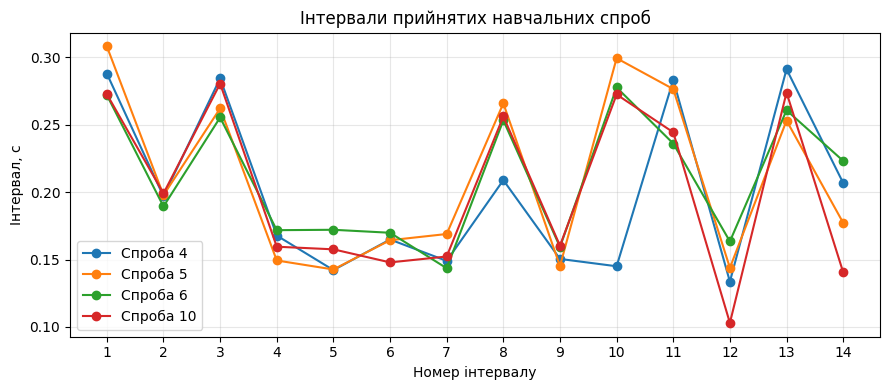


Серія 1: Власник; α=0.05; поріг=0.9
Спроба | P | рішення | відхилено до порівняння
1 | — | Відмовлено | Так
2 | 1.000 | Допущено | Ні
3 | — | Відмовлено | Так
4 | 1.000 | Допущено | Ні
5 | 1.000 | Допущено | Ні
6 | 1.000 | Допущено | Ні
7 | 1.000 | Допущено | Ні
8 | — | Відмовлено | Так
9 | — | Відмовлено | Так
10 | 1.000 | Допущено | Ні
Помилка першого роду: 4/10 = 40.0%
Відхилено до порівняння: 4

Серія 2: Інша людина; α=0.05; поріг=0.9
Спроба | P | рішення | відхилено до порівняння
1 | — | Відмовлено | Так
2 | — | Відмовлено | Так
3 | — | Відмовлено | Так
4 | — | Відмовлено | Так
5 | — | Відмовлено | Так
6 | — | Відмовлено | Так
7 | — | Відмовлено | Так
8 | 0.000 | Відмовлено | Ні
9 | — | Відмовлено | Так
10 | — | Відмовлено | Так
Помилка другого роду: 0/10 = 0.0%
Відхилено до порівняння: 9

Підсумкові результати

α=0.05; поріг=0.9
Власник: помилка першого роду 4/10 = 40.0%; відхилено до порівняння 4.
Інша людина: помилка другого роду 0/10 = 0.0%; відхилено до порівняння 9.
Загальн

In [6]:
path = folder / "etalon.json"
if not path.exists():
    print("Спочатку проведіть навчання.")
else:
    profile = json.loads(path.read_text(encoding="utf-8"))
    print("Фраза:", profile["phrase"], "| потрібно інтервалів:", profile["n"])
    print("Навчальних спроб:", len(profile["training"]))
    print("Збережених зразків:", len(profile["samples"]))
    print("Відхилених навчальних спроб:", profile["rejected_count"])
    print("Спроба | інтервалів | середнє, с | дисперсія, с² | прийнято")
    for s in profile["training"]:
        mean = "—" if s["mean"] is None else f"{s['mean']:.6f}"
        var = "—" if s["var"] is None else f"{s['var']:.8f}"
        print(f"{s['attempt']} | {len(s['values'])}/{profile['n']} | {mean} | {var} | "
              + ("Так" if s["valid"] else "Ні"))
        if not s["valid"]:
            print("  Причина:", s["reason"])
    scores = consistency(profile["samples"])
    if scores:
        print("\nПорівняння навчальних зразків між собою (α=0,05):")
        for s, score in zip(profile["samples"], scores):
            print(f"Навчальна спроба №{s['attempt']}: {score:.3f}")
    if profile["samples"]:
        plt.figure(figsize=(9, 4))
        for s in profile["samples"]:
            plt.plot(range(1, profile["n"] + 1), s["values"], marker="o", label=f"Спроба {s['attempt']}")
        plt.xlabel("Номер інтервалу")
        plt.ylabel("Інтервал, с")
        plt.title("Інтервали прийнятих навчальних спроб")
        plt.xticks(range(1, profile["n"] + 1))
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("Зразків немає. Потрібне нове навчання.")
    path = folder / "checks.json"
    records = json.loads(path.read_text(encoding="utf-8")) if path.exists() else []
    records = [r for r in records if r["profile_id"] == profile["id"]]
    if not records:
        print("\nІз цими зразками ще не проводили перевірку.")
    else:
        series = list(dict.fromkeys(r["series_id"] for r in records))
        for number, sid in enumerate(series, 1):
            group = [r for r in records if r["series_id"] == sid]
            first = group[0]
            print(f"\nСерія {number}: {first['person']}; α={first['alpha']}; поріг={first['threshold']}")
            print("Спроба | P | рішення | відхилено до порівняння")
            for r in group:
                prob = "—" if r["p"] is None else f"{r['p']:.3f}"
                print(f"{r['attempt']} | {prob} | " + ("Допущено" if r["accepted"] else "Відмовлено")
                      + " | " + ("Ні" if r["sample"]["valid"] else "Так"))
            n0, n1, m0, n2 = error_rates(group)
            if first["person"] == "Власник":
                print(f"Помилка першого роду: {n1}/{n0} = {n1 / n0:.1%}")
            else:
                print(f"Помилка другого роду: {n2}/{m0} = {n2 / m0:.1%}")
            print("Відхилено до порівняння:", sum(not r["sample"]["valid"] for r in group))
        print("\nПідсумкові результати")
        for alpha, threshold in sorted({(r["alpha"], r["threshold"]) for r in records}):
            group = [r for r in records if r["alpha"] == alpha and r["threshold"] == threshold]
            print(f"\nα={alpha}; поріг={threshold}")
            for person in ("Власник", "Інша людина"):
                subset = [r for r in group if r["person"] == person]
                if not subset:
                    print(person + ": немає перевірок.")
                    continue
                errors = sum((not r["accepted"]) if person == "Власник" else r["accepted"] for r in subset)
                kind = "першого" if person == "Власник" else "другого"
                bad = sum(not r["sample"]["valid"] for r in subset)
                print(f"{person}: помилка {kind} роду {errors}/{len(subset)} = {errors / len(subset):.1%}; відхилено до порівняння {bad}.")
            n0, n1, m0, n2 = error_rates(group)
            correct = n0 - n1 + m0 - n2
            print(f"Загальна точність: {correct}/{len(group)} = {correct / len(group):.1%}")
            if not n0 or not m0:
                print("Для повного результату проведіть перевірку і власника, й іншої людини.")
